# Cluster Analysis of Selected Language Sample

### Common Setup

In [1]:
# Setting system path and project root
import os
import sys

PROJECT_ROOT_DIR = os.path.abspath('../../')
sys.path.append(PROJECT_ROOT_DIR) # bringing system path to project root

def get_fp(relative_path):
    return os.path.join(PROJECT_ROOT_DIR, relative_path)

### Reading Language Sample with Resource Category Data

In [2]:
sample_files = [
    "data_dir/fineweb2_metadata/l2v_nested_samples/5.csv",
    "data_dir/fineweb2_metadata/l2v_nested_samples/10.csv",
    "data_dir/fineweb2_metadata/l2v_nested_samples/22.csv",
    "data_dir/fineweb2_metadata/l2v_nested_samples/46.csv",
    "data_dir/fineweb2_metadata/l2v_nested_samples/96.csv",
    "data_dir/fineweb2_metadata/l2v_nested_samples/200.csv",
]

In [3]:
import warnings

# Ignore the specific warning emitted by lang2vec
warnings.filterwarnings(
    "ignore",
    message=r"pkg_resources is deprecated as an API.*",
    category=UserWarning,
    module=r"lang2vec\.lang2vec"
)

from lang2vec.lang2vec import *
def get_dist_matrix(lang_codes, distance_name):
        with zf(DISTANCES_FILE, 'r') as zp:
                data = sparse.load_npz(zp.open(map_distance_to_filename(distance_name)))

        present_idxs = np.array([DISTANCE_LANGUAGES.index(code) for code in lang_codes])
        dist_mat = [[data[lang2_idx, lang1_idx] if lang1_idx > lang2_idx else data[lang1_idx, lang2_idx]  for lang2_idx in present_idxs] for lang1_idx in present_idxs]
        return dist_mat

In [4]:
# Fetch distance matrix
eval_distances = {
    "genetic",
    "geographic", 
    "syntactic",
    "inventory",
    "phonological",
    "featural"
}

# Lang2Vec provides a collection of supported language identifiers
available_langs = set(DISTANCE_LANGUAGES)          # e.g. {'eng', 'fra', ...}


>>>>>>>>>>>>>>>>>>>>>>>> Running analysis for: data_dir/fineweb2_metadata/l2v_nested_samples/5.csv <<<<<<<<<<<<<<<<<<<<<<<<
Shape of sample dataframe: (6, 15)

Unique values in 'subset' (6 total):

Unique values in 'code' (5 total):

Unique values in 'name' (5 total):

Unique values in 'script' (4 total):

Unique values in 'family' (5 total):


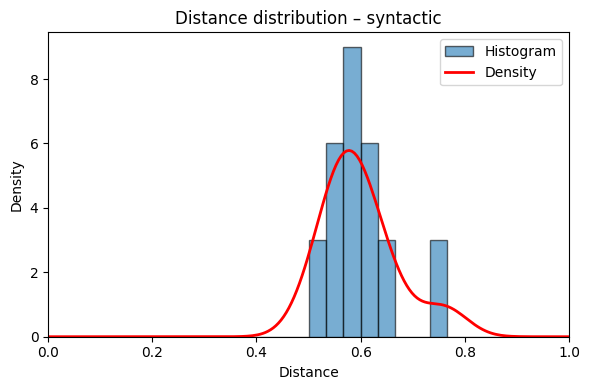

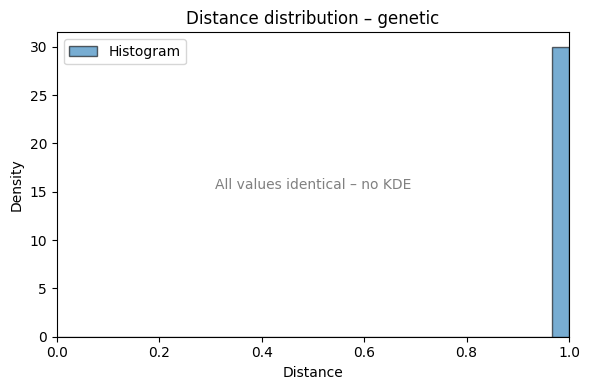

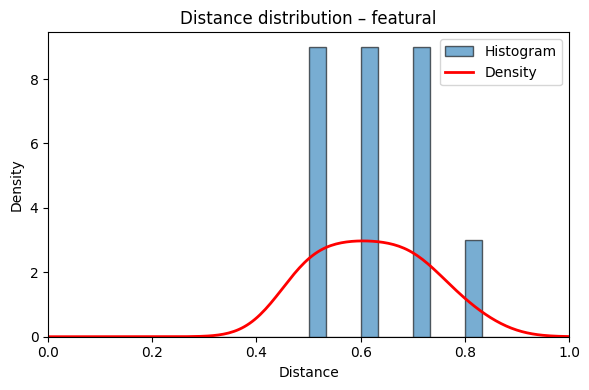

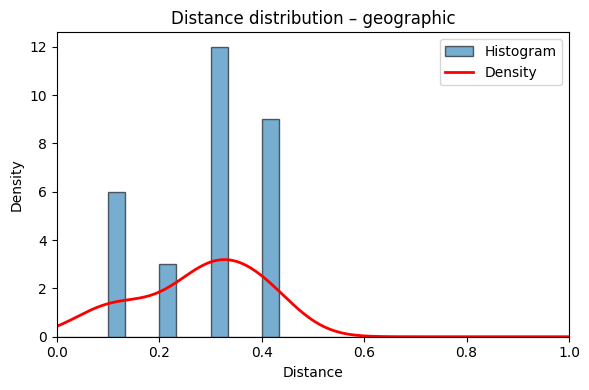

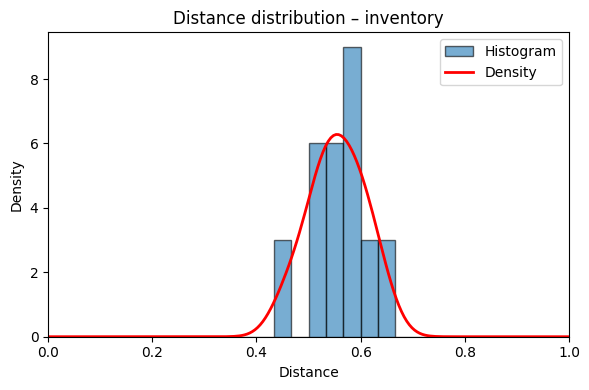

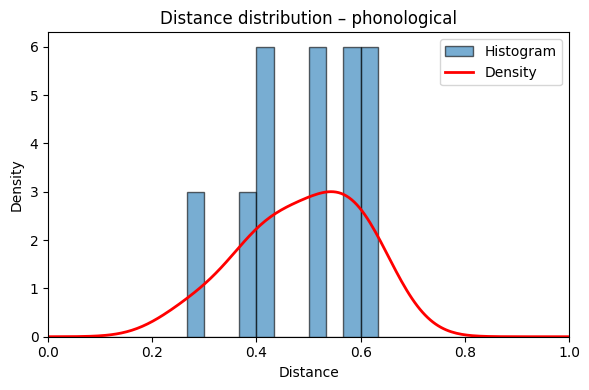

Original dim: 30, reduced dim: 4


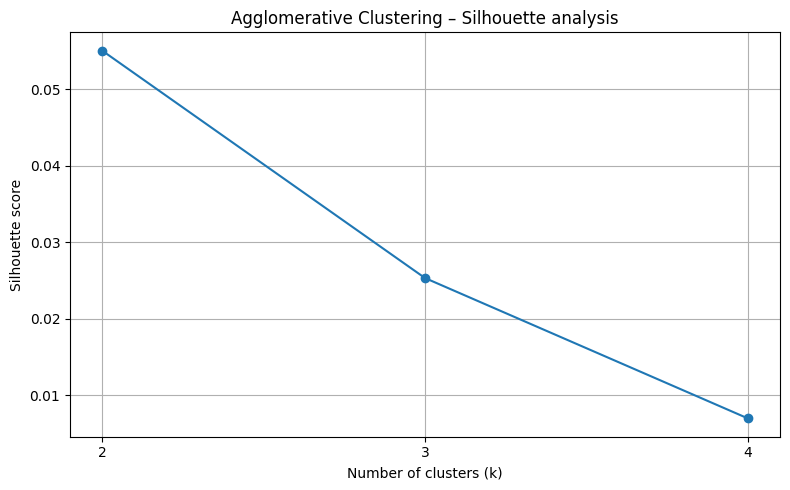

Highest silhouette score: 0.0550 (achieved with k = 2)

>>>>>>>>>>>>>>>>>>>>>>>> Running analysis for: data_dir/fineweb2_metadata/l2v_nested_samples/10.csv <<<<<<<<<<<<<<<<<<<<<<<<
Shape of sample dataframe: (12, 15)

Unique values in 'subset' (12 total):

Unique values in 'code' (10 total):

Unique values in 'name' (10 total):

Unique values in 'script' (6 total):

Unique values in 'family' (9 total):


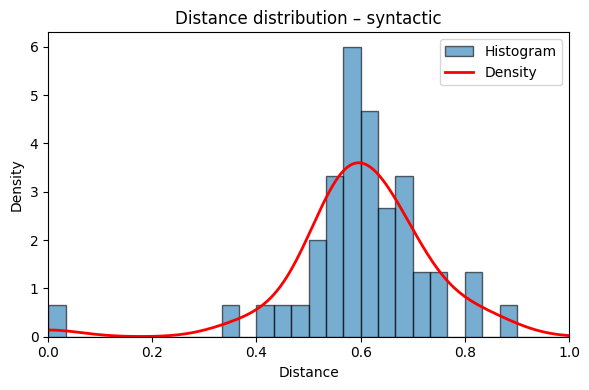

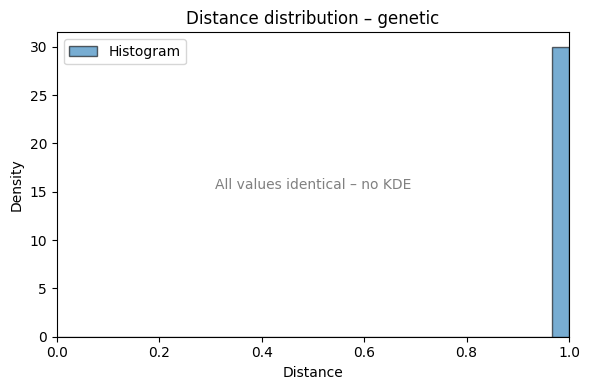

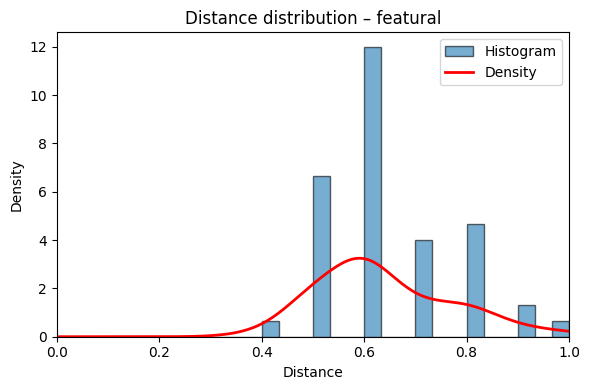

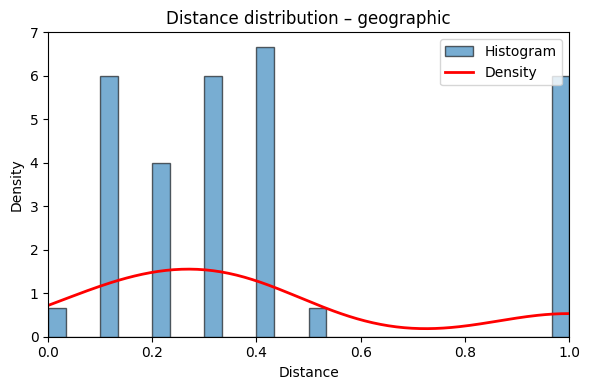

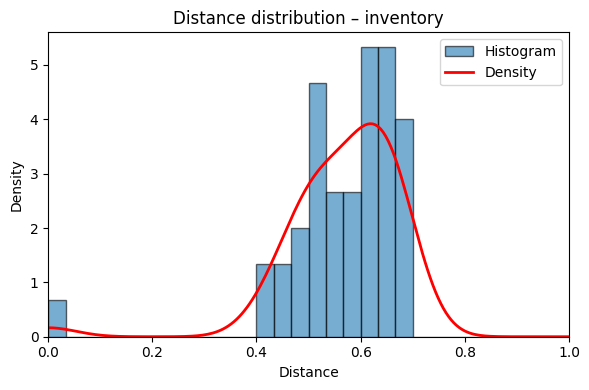

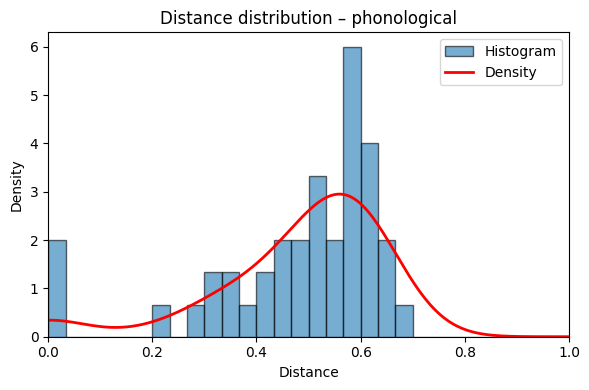

Original dim: 60, reduced dim: 8


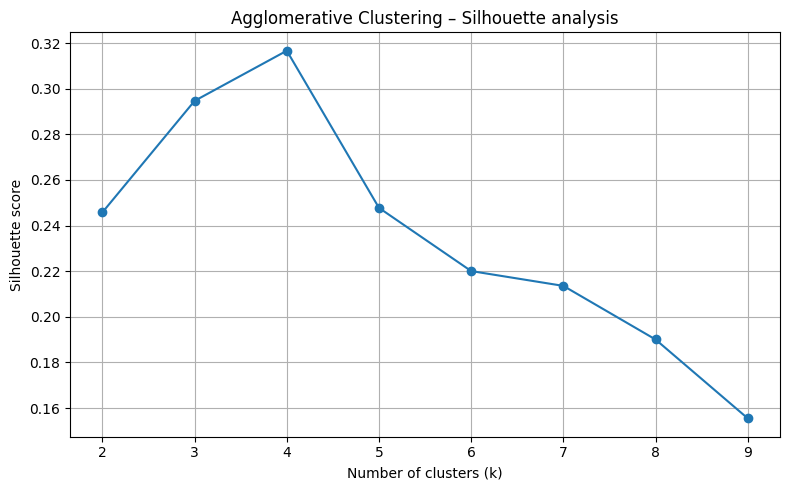

Highest silhouette score: 0.3167 (achieved with k = 4)

>>>>>>>>>>>>>>>>>>>>>>>> Running analysis for: data_dir/fineweb2_metadata/l2v_nested_samples/22.csv <<<<<<<<<<<<<<<<<<<<<<<<
Shape of sample dataframe: (25, 15)

Unique values in 'subset' (25 total):

Unique values in 'code' (22 total):

Unique values in 'name' (22 total):

Unique values in 'script' (9 total):

Unique values in 'family' (17 total):


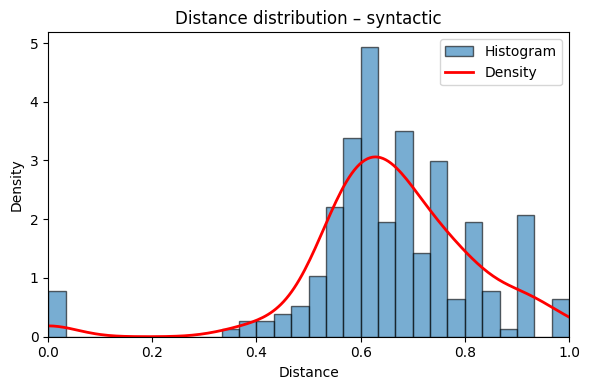

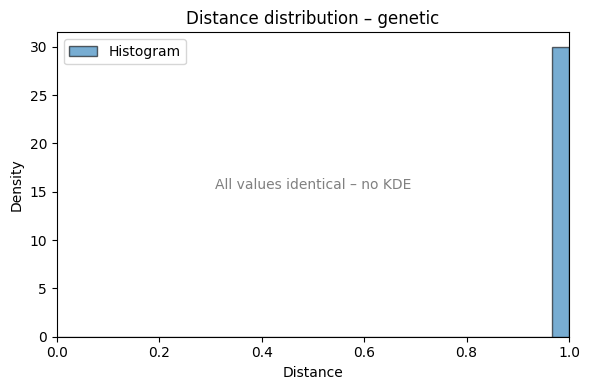

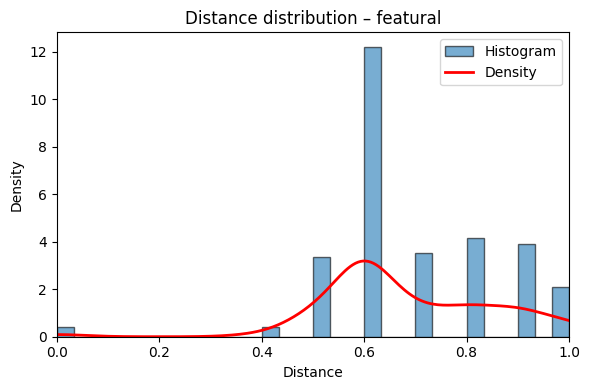

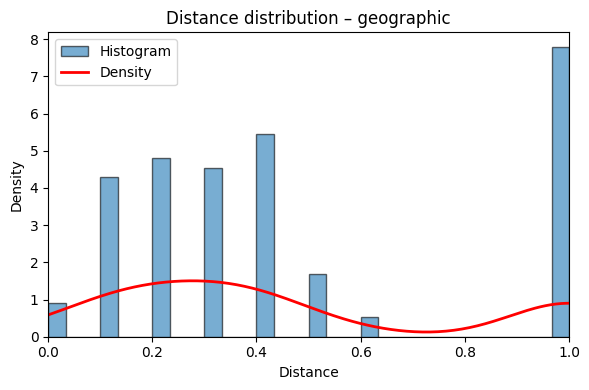

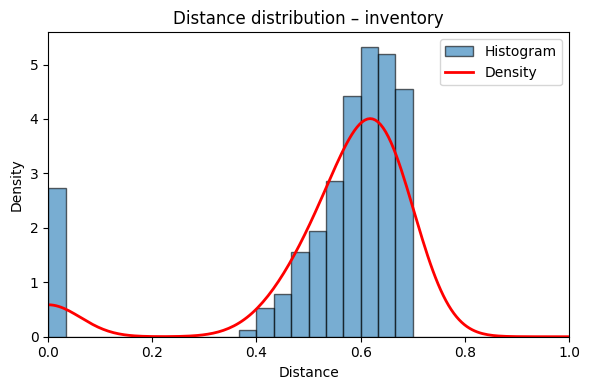

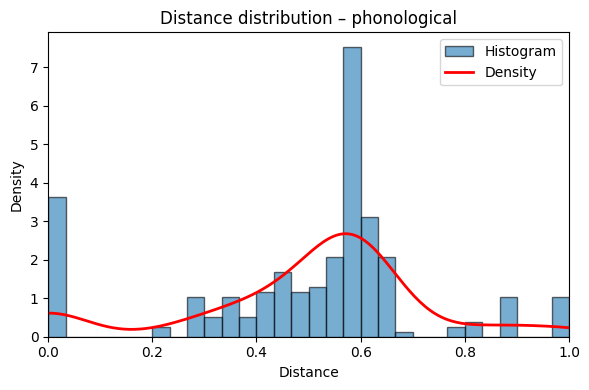

Original dim: 132, reduced dim: 17


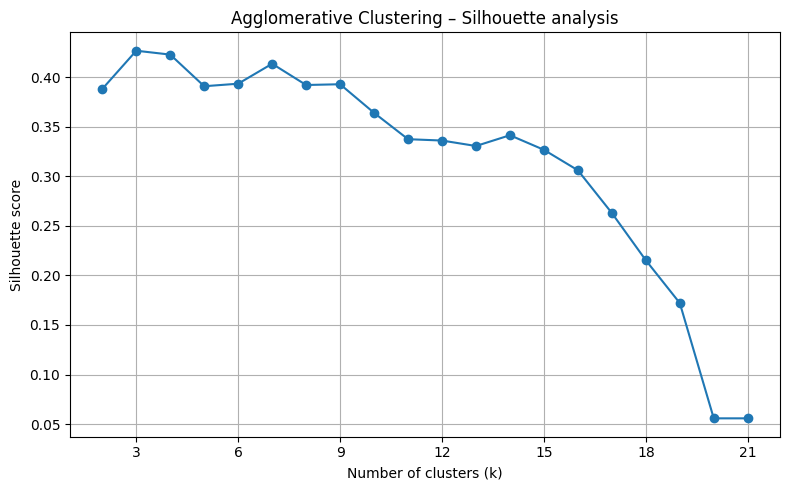

Highest silhouette score: 0.4267 (achieved with k = 3)

>>>>>>>>>>>>>>>>>>>>>>>> Running analysis for: data_dir/fineweb2_metadata/l2v_nested_samples/46.csv <<<<<<<<<<<<<<<<<<<<<<<<
Shape of sample dataframe: (49, 15)

Unique values in 'subset' (49 total):

Unique values in 'code' (46 total):

Unique values in 'name' (46 total):

Unique values in 'script' (9 total):

Unique values in 'family' (32 total):


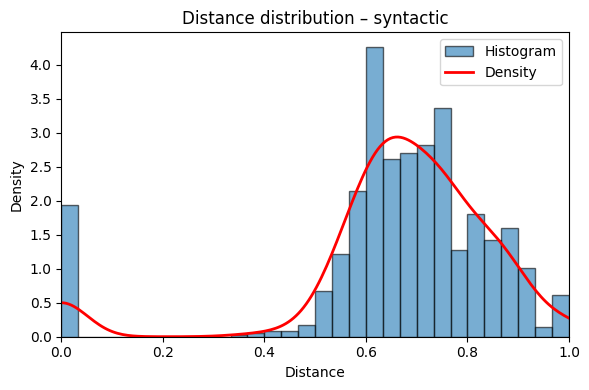

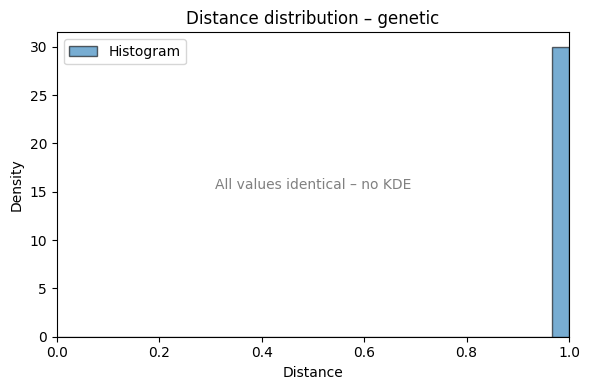

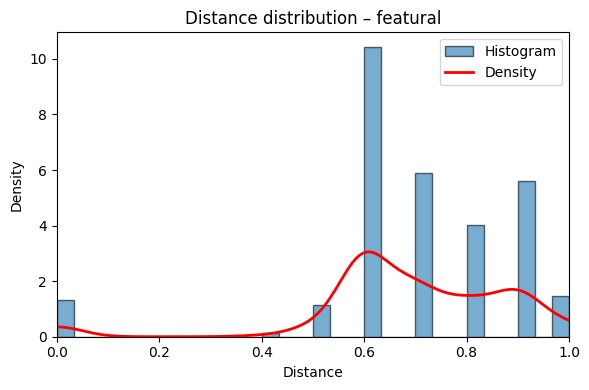

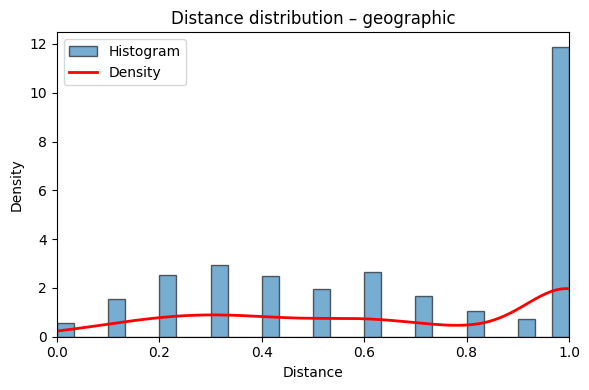

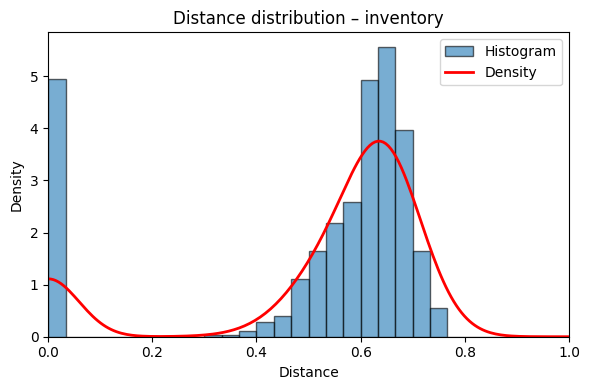

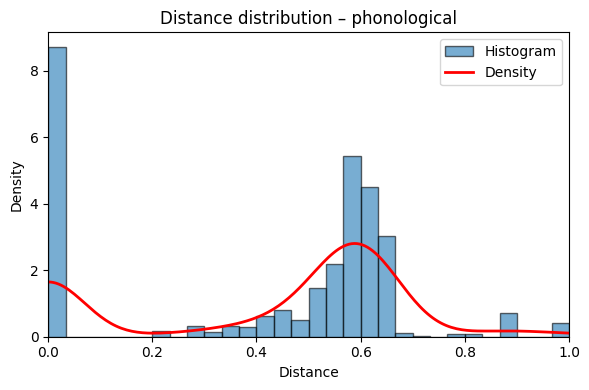

Original dim: 276, reduced dim: 28


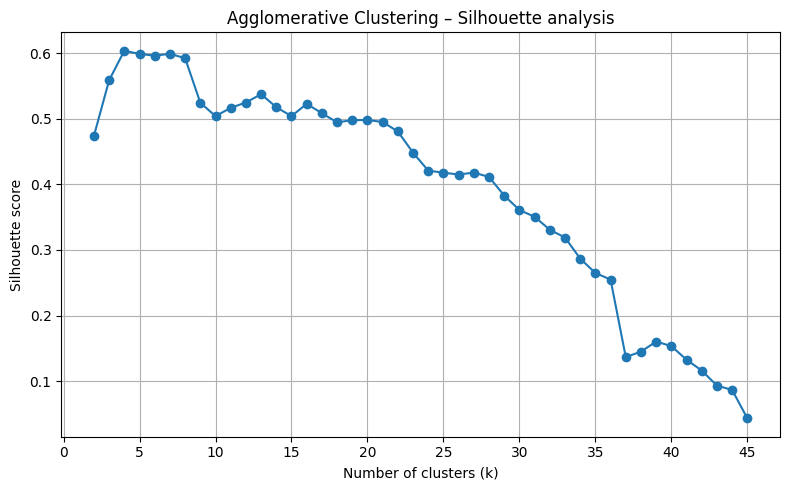

Highest silhouette score: 0.6036 (achieved with k = 4)

>>>>>>>>>>>>>>>>>>>>>>>> Running analysis for: data_dir/fineweb2_metadata/l2v_nested_samples/96.csv <<<<<<<<<<<<<<<<<<<<<<<<
Shape of sample dataframe: (101, 15)

Unique values in 'subset' (101 total):

Unique values in 'code' (96 total):

Unique values in 'name' (96 total):

Unique values in 'script' (16 total):

Unique values in 'family' (43 total):


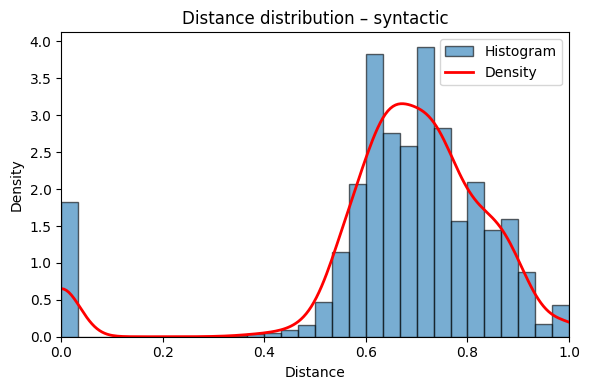

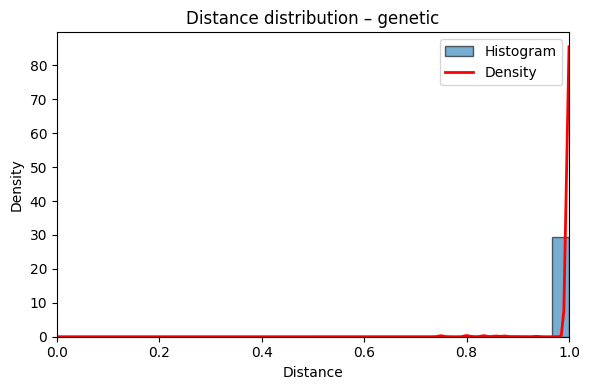

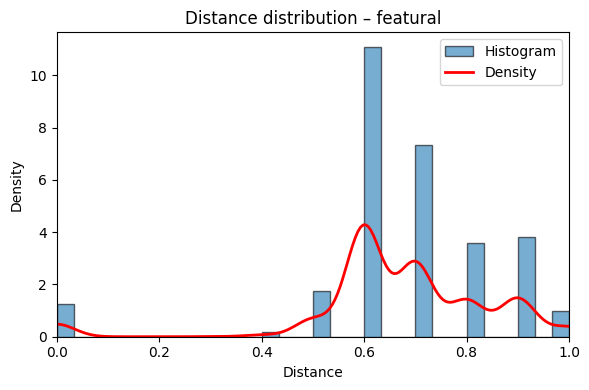

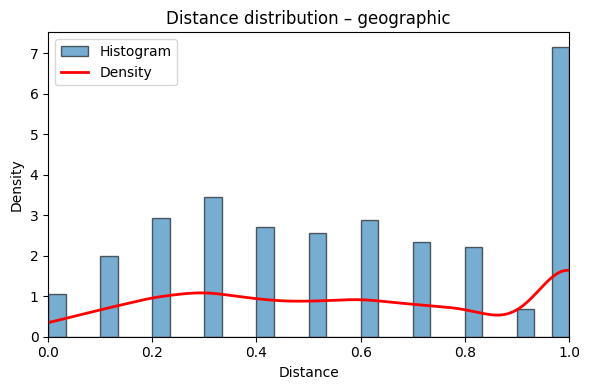

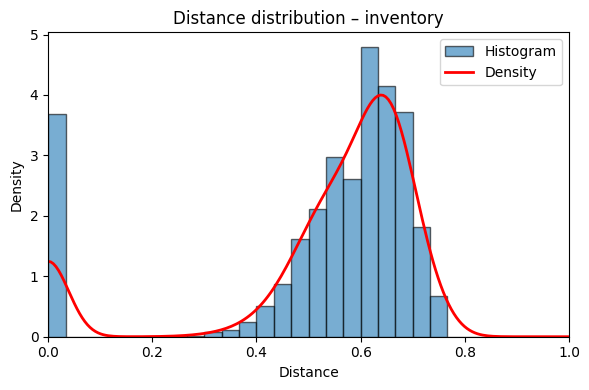

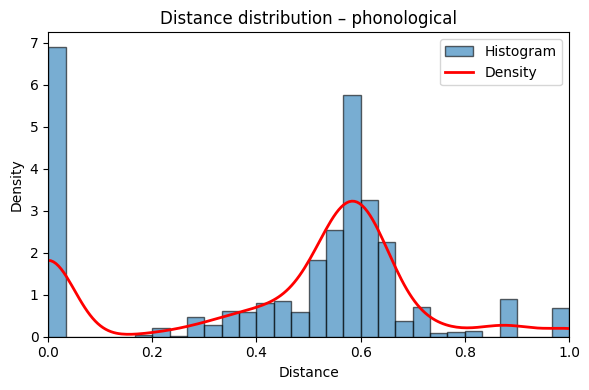

Original dim: 576, reduced dim: 31


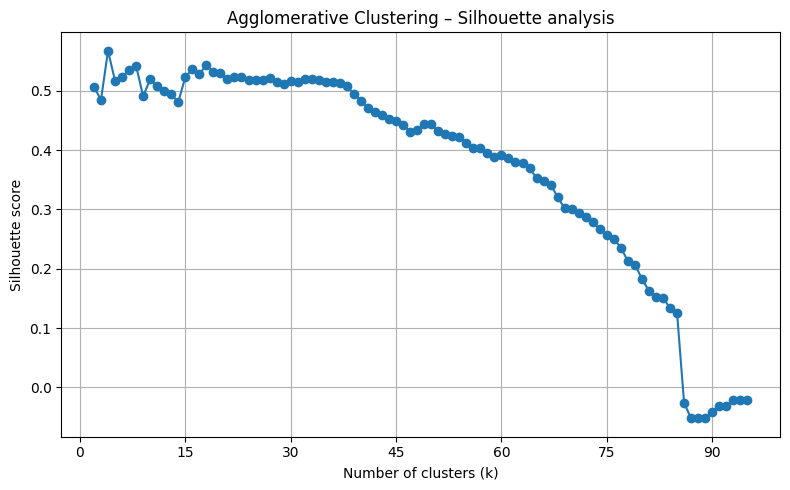

Highest silhouette score: 0.5676 (achieved with k = 4)

>>>>>>>>>>>>>>>>>>>>>>>> Running analysis for: data_dir/fineweb2_metadata/l2v_nested_samples/200.csv <<<<<<<<<<<<<<<<<<<<<<<<
Shape of sample dataframe: (214, 15)

Unique values in 'subset' (214 total):

Unique values in 'code' (200 total):

Unique values in 'name' (200 total):

Unique values in 'script' (25 total):

Unique values in 'family' (43 total):


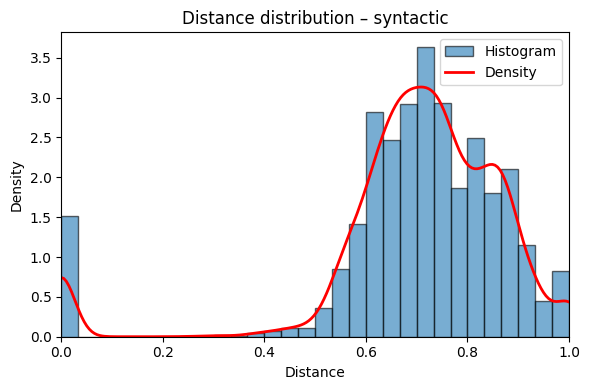

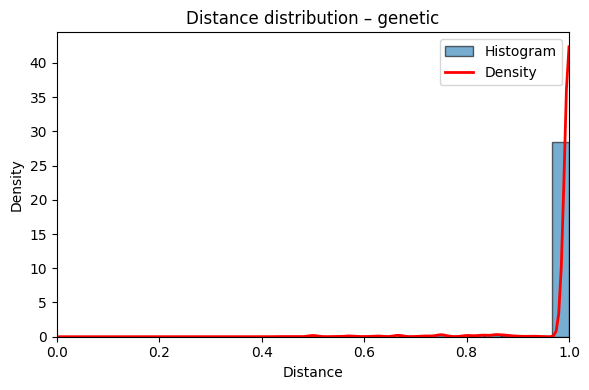

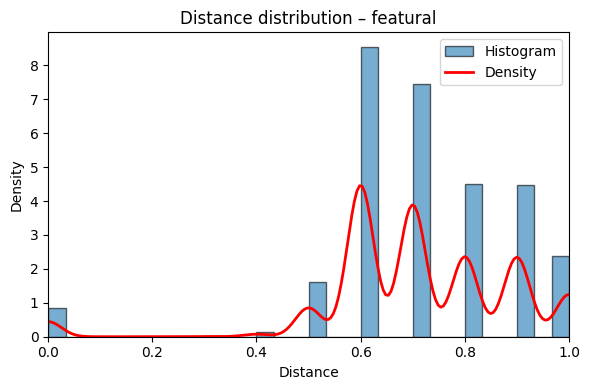

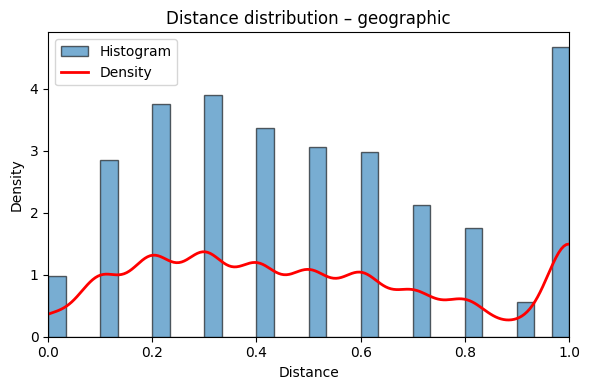

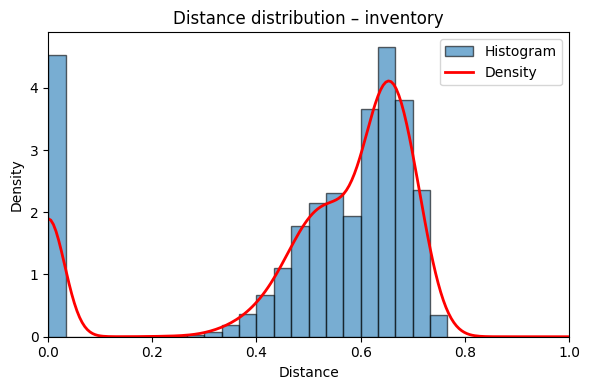

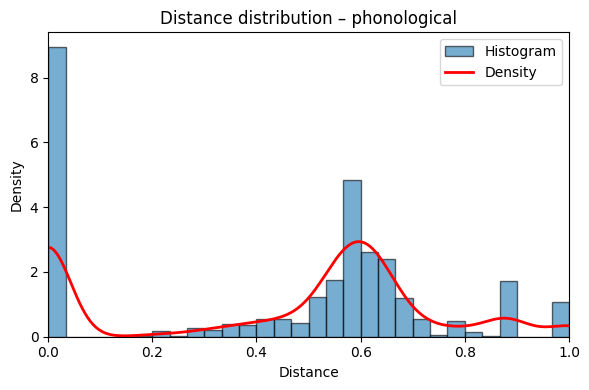

Original dim: 1200, reduced dim: 19


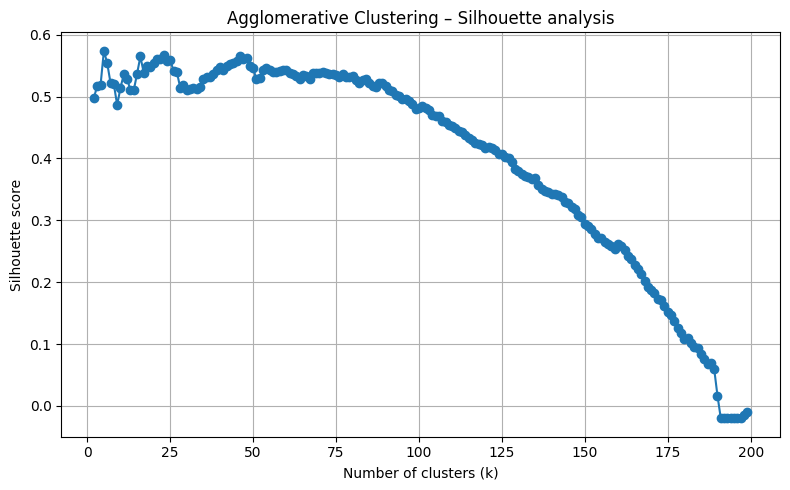

Highest silhouette score: 0.5741 (achieved with k = 5)


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

def run_cluster_analysis(sample_lang_doc_distr_df):

    print(f'Shape of sample dataframe: {sample_lang_doc_distr_df.shape}')

    columns_of_interest = ["subset", "code", "name", "script", "family"]
    for col in columns_of_interest:
        if col in sample_lang_doc_distr_df.columns:
            uniques = sample_lang_doc_distr_df[col].dropna().unique()
            print(f"\nUnique values in '{col}' ({len(uniques)} total):")
        else:
            print(f"\nColumn '{col}' not found in the CSV.")

    lang_codes = sample_lang_doc_distr_df['code'].astype(str).unique()

    dist_matrix_map = {distance_name: get_dist_matrix(lang_codes, distance_name)
                       for distance_name in eval_distances}
    
    # Visualise distribution of each individual distance matrix
    for name, mat in dist_matrix_map.items():
        mat_arr   = np.asarray(mat, dtype=float)
        tril_vals = mat_arr[np.tril_indices_from(mat_arr, k=-1)]

        plt.figure(figsize=(6, 4))
        plt.hist(tril_vals, bins=30, range=(0, 1), density=True,
                 edgecolor='black', alpha=0.6, label='Histogram')
        if np.var(tril_vals) > 0:
            from scipy.stats import gaussian_kde
            jittered = tril_vals + np.random.normal(scale=1e-12, size=tril_vals.shape)
            kde = gaussian_kde(jittered)
            xs = np.linspace(0, 1, 200)
            plt.plot(xs, kde(xs), color='red', lw=2, label='Density')
        else:
            plt.text(0.5, 0.5, 'All values identical – no KDE',
                     transform=plt.gca().transAxes,
                     ha='center', va='center', color='gray')
        plt.title(f'Distance distribution – {name}')
        plt.xlabel('Distance')
        plt.ylabel('Density')
        plt.xlim(0, 1)
        plt.legend()
        plt.tight_layout()
        plt.show()

    distance_names = list(dist_matrix_map.keys())
    n = len(lang_codes)

    mats = []                     # will hold N×N (raw) matrices
    for name in distance_names:
        mat = np.asarray(dist_matrix_map[name], dtype=float)
        # No normalisation – use the raw distance values directly
        mats.append(mat)

    X = np.hstack(mats)   # X[i] = [row_i of mat1, …, row_i of mat6]
    
    # Reducing dimensions to remove redundant dimensions and can make clusters more apparent.
    pca = PCA(n_components=0.95, random_state=42)
    X_reduced = pca.fit_transform(X)

    print(f"Original dim: {X.shape[1]}, reduced dim: {X_reduced.shape[1]}")

    range_k = list(range(2, n))
    silhouette_scores = []   # will hold scores for Agglomerative clustering
    # inertias list removed – not applicable for hierarchical clustering

    for k in range_k:
        # Agglomerative clustering with cosine distance (average linkage)
        agg = AgglomerativeClustering(
            n_clusters=k,
            metric='cosine',        # use cosine similarity as distance metric as mentioned in lang2vec repo
            linkage='average'
        )
        labels = agg.fit_predict(X_reduced)

        sil = silhouette_score(X_reduced, labels, metric='cosine')
        silhouette_scores.append(sil)

    # Plotting
    _, ax = plt.subplots(1, 1, figsize=(8, 5))
    ax.plot(range_k, silhouette_scores, marker='o')
    ax.set_xlabel('Number of clusters (k)')
    ax.set_ylabel('Silhouette score')
    ax.set_title('Agglomerative Clustering – Silhouette analysis')
    ax.grid(True)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.show()

    best_idx = np.argmax(silhouette_scores)
    best_k   = range_k[best_idx]
    best_score = silhouette_scores[best_idx]
    print(f"Highest silhouette score: {best_score:.4f} (achieved with k = {best_k})")


# Loop over the files and call the function
for rel_path in sample_files:
    csv_path = get_fp(rel_path)
    df = pd.read_csv(csv_path)
    print(f"\n>>>>>>>>>>>>>>>>>>>>>>>> Running analysis for: {rel_path} <<<<<<<<<<<<<<<<<<<<<<<<")
    run_cluster_analysis(df)

In [6]:
## Obsolete testing code
# DISTANCE_LANGUAGES
# data[0, 4]
# #dist_mat
# genetic_distance('rus','ajz')
# present_codes
# random_index = 44
# lang_sel = present_codes[random_index]
# print(lang_sel)
# lang_ind = present_idxs[random_index]
# print(lang_ind)
# print(dist_mat[random_index])
# ext_gen_dist = [genetic_distance(lang, present_codes[random_index]) for lang in present_codes]
# print(ext_gen_dist)
# print(ext_gen_dist == dist_mat[random_index])
# dist_mat = np.asarray(dist_mat, dtype=np.float64)
# print(dist_mat)